In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os, sys

from matplotlib import colormaps
import matplotlib.colors as mcolors
import matplotlib.cm as cm

In [2]:
def craccel_mach(mach, params):
    '''As in Kang & Jones 2007'''
    if mach <= 2:
        return 1.96e-3 * (mach**2 - 1)
    else:
        return np.sum(params * np.array( [(mach - 1)**n for n in range(0,5)] ) / mach**4)
    
def craccel_mgob(theta_B, theta_crit=np.pi/4, delta_B=np.pi/18):
    '''As in Pais et al 2018'''
    return 0.5 * (np.tanh( (theta_crit - theta_B) / delta_B) + 1)


def craccel_machs(machs, params):
    return np.array([craccel_mach(m, params) for m in machs])

Plot for dependence of mach number only

In [3]:
# define the parameters
b_arr = np.array([5.46, -9.78, 4.17, -0.334, 0.57])

# dependence of mach number only
mach_arr = np.logspace(0, 3, 1000)
craccel_mach_arr = craccel_machs(mach_arr, b_arr)

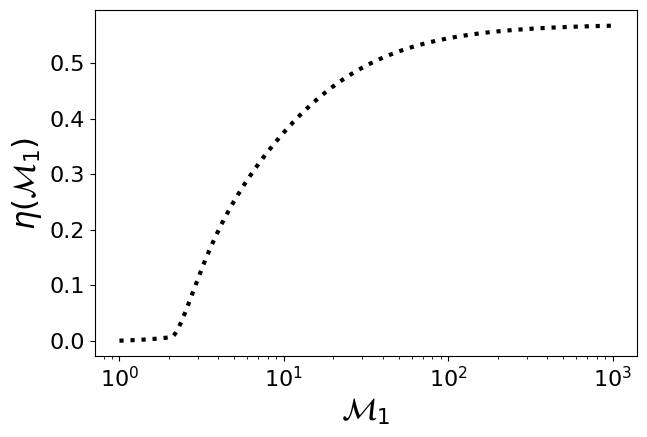

In [4]:
fig, ax = plt.subplots(figsize=(7,4.5))

ax.plot(mach_arr, craccel_mach_arr, ls=":", color="k", lw=3.0)

ax.set_xlabel(r"$\mathcal{M}_1$", fontsize=22)

ax.set_ylabel(r"$\eta(\mathcal{M}_1)$", fontsize=22)

ax.tick_params(axis='both', which='major', labelsize=16)
ax.tick_params(axis='both', which='minor', labelsize=14)

ax.set_xscale("log")

fig.savefig(os.path.join("/home/watanabe/Projects/meerkat_bowshocks/figures/sod_crinj", "cracceleff_mach.pdf"), dpi=300, bbox_inches="tight")

plot just as function of magnetic obliquity

In [5]:
thetaB_arr = np.linspace(0, 90, 1000)
craccel_mgob_arr = craccel_mgob(np.deg2rad(thetaB_arr))

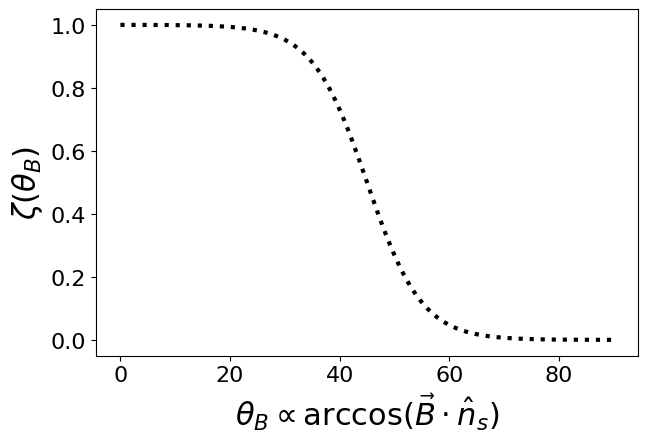

In [6]:
fig, ax = plt.subplots(figsize=(7,4.5))

ax.plot(thetaB_arr, craccel_mgob_arr, ls=":", color="k", lw=3.0)

ax.set_xlabel(r"$\theta_B \propto \arccos(\vec{B} \cdot \hat{n}_s)$", fontsize=22)

ax.set_ylabel(r"$\zeta(\theta_B)$", fontsize=22)

ax.tick_params(axis='both', which='major', labelsize=16)
ax.tick_params(axis='both', which='minor', labelsize=14)

# ax.set_xscale("log")

# fig.savefig(os.path.join("/home/watanabe/Projects/meerkat_bowshocks/figures/sod_crinj", "cracceleff_mach.pdf"), dpi=300, bbox_inches="tight")

plot with different magnetic obliquity values

In [7]:
# dependence with theta_B, fixed values of mach
mach_arr = np.logspace(0, 2, 1000)
thetaB_list = [0.0, 30.0, 45.0, 60.0, 90.0]

craccel_arr = np.zeros((len(thetaB_list), len(mach_arr)))
for i, thetaB in enumerate(thetaB_list):
    craccel_arr[i,:] = craccel_mgob(np.deg2rad(thetaB)) * craccel_mach_arr

In [8]:
# create color based on normalization
norm = mcolors.Normalize(vmin=min(thetaB_list), vmax=max(thetaB_list))
cmap = colormaps["copper"]

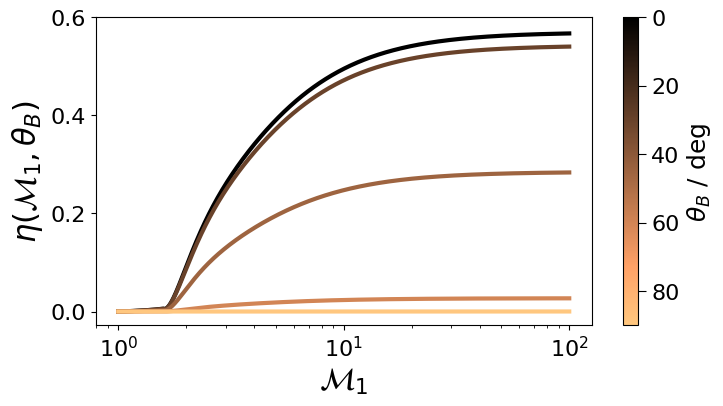

In [12]:
fig, ax = plt.subplots(figsize=(8,4))

for i, thetaB in enumerate(thetaB_list):
    ax.plot(mach_arr, craccel_arr[i,:], ls="-", color=cmap(norm(thetaB)), lw=3.0, label=fr"$\theta_B$ = {thetaB:.0f}$^\circ$")

ax.set_xlabel(r"$\mathcal{M}_1$", fontsize=22)
ax.set_ylabel(r"$\eta(\mathcal{M}_1, \theta_B)$", fontsize=22)

ax.tick_params(axis='both', which='major', labelsize=16)
ax.tick_params(axis='both', which='minor', labelsize=14)

ax.set_xscale("log")
# ax.set_yscale("log")

ax.set_ylim(ymax=0.6)

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm, ax=ax)
cbar.ax.set_ylabel(r"$\theta_B$ / deg", fontsize=18)
cbar.ax.invert_yaxis()
cbar.ax.tick_params(axis='both', which='major', size=6, labelsize=16)
cbar.ax.tick_params(axis='both', which='minor', size=4, labelsize=16)

fig.savefig(os.path.join("/home/watanabe/Projects/meerkat_bowshocks/figures/sod_crinj", "cracceleff.pdf"), dpi=300, bbox_inches="tight")